In [10]:
import os
import joblib
import numpy as np
import pandas as pd


In [11]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor


In [12]:
os.makedirs("models", exist_ok=True)
os.makedirs("outputs", exist_ok=True)


In [13]:
# STEP 1: Load data
df = pd.read_csv("food_waste_dataset.csv")
print("Original shape:", df.shape)


Original shape: (5012, 15)


In [14]:
# STEP 2: Basic cleaning
df["date"] = pd.to_datetime(df["date"], errors="coerce")
df = df.drop_duplicates().copy()

In [15]:
# Add useful calendar features
df["year"] = df["date"].dt.year
df["month"] = df["date"].dt.month
df["week_of_year"] = df["date"].dt.isocalendar().week.astype(int)
df["is_weekend"] = (df["day_of_week"] >= 5).astype(int)


In [16]:
# IMPORTANT: We do not use food_waste_kg itself or post-event information as features.
target = "food_waste_kg"

In [17]:
features = [
    "meals_served",
    "kitchen_staff",
    "temperature_C",
    "humidity_percent",
    "day_of_week",
    "month",
    "week_of_year",
    "is_weekend",
    "special_event",
    "holiday",
    "past_waste_kg",
    "meal_type",
    "menu_type",
    "staff_experience"
]

In [18]:
X = df[features]
y = df[target]


In [19]:
# STEP 3: Chronological split (better for a forecasting-style problem)
df_sorted = df.sort_values("date").reset_index(drop=True)
X = df_sorted[features]
y = df_sorted[target]

In [20]:
split_index = int(len(df_sorted) * 0.80)
X_train, X_test = X.iloc[:split_index], X.iloc[split_index:]
y_train, y_test = y.iloc[:split_index], y.iloc[split_index:]


In [21]:
numeric_features = [
    "meals_served", "kitchen_staff", "temperature_C", "humidity_percent",
    "day_of_week", "month", "week_of_year", "is_weekend",
    "special_event", "holiday", "past_waste_kg"
]

In [22]:
categorical_features = ["meal_type", "menu_type", "staff_experience"]

numeric_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

In [23]:
categorical_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

In [24]:
models = {
    "Linear Regression": LinearRegression(),
    "Decision Tree": DecisionTreeRegressor(max_depth=8, random_state=42),
    "Random Forest": RandomForestRegressor(
        n_estimators=300, max_depth=12, random_state=42, n_jobs=-1
    ),
    "Gradient Boosting": GradientBoostingRegressor(
        n_estimators=200, learning_rate=0.05, max_depth=3, random_state=42
    )
}

In [25]:
results = []
trained_pipelines = {}

In [26]:
# STEP 4: Train and evaluate models
for name, model in models.items():
    pipe = Pipeline([
        ("preprocessor", preprocessor),
        ("model", model)
    ])

    pipe.fit(X_train, y_train)
    pred = pipe.predict(X_test)

    mae = mean_absolute_error(y_test, pred)
    rmse = np.sqrt(mean_squared_error(y_test, pred))
    r2 = r2_score(y_test, pred)

    results.append({
        "Model": name,
        "MAE_kg": round(mae, 3),
        "RMSE_kg": round(rmse, 3),
        "R2": round(r2, 3)
    })
    trained_pipelines[name] = pipe

results_df = pd.DataFrame(results).sort_values("MAE_kg")
print("\nMODEL COMPARISON")
print(results_df.to_string(index=False))
results_df.to_csv("outputs/model_comparison.csv", index=False)



MODEL COMPARISON
            Model  MAE_kg  RMSE_kg    R2
Linear Regression   3.787    4.728 0.597
Gradient Boosting   3.849    4.839 0.578
    Random Forest   3.966    4.989 0.551
    Decision Tree   4.510    5.663 0.422


In [27]:
# STEP 5: Select best model by lowest MAE
best_name = results_df.iloc[0]["Model"]
best_model = trained_pipelines[best_name]
joblib.dump(best_model, "models/food_waste_model.pkl")

with open("models/best_model.txt", "w", encoding="utf-8") as f:
    f.write(best_name)

print("\nBest model:", best_name)
print("Saved: models/food_waste_model.pkl")



Best model: Linear Regression
Saved: models/food_waste_model.pkl


In [28]:
# STEP 6: Save a few actual-vs-predicted values
pred_best = best_model.predict(X_test)
comparison = X_test.copy()
comparison["Actual_Waste_kg"] = y_test.values
comparison["Predicted_Waste_kg"] = np.round(pred_best, 2)
comparison.to_csv("outputs/test_predictions.csv", index=False)


In [29]:
print("\nTraining completed successfully.")



Training completed successfully.


In [30]:
import joblib
import pandas as pd

In [31]:
MODEL_PATH = "models/food_waste_model.pkl"

In [32]:
model = joblib.load(MODEL_PATH)

In [33]:
# Example: replace these values with real kitchen/restaurant data
new_data = pd.DataFrame([{
    "meals_served": 500,
    "kitchen_staff": 7,
    "temperature_C": 31.0,
    "humidity_percent": 70.0,
    "day_of_week": 4,       # Friday; Monday=0 ... Sunday=6
    "month": 10,
    "week_of_year": 41,
    "is_weekend": 0,
    "special_event": 1,
    "holiday": 0,
    "past_waste_kg": 22.5,
    "meal_type": "Lunch",
    "menu_type": "Veg",
    "staff_experience": "Intermediate"
}])


In [34]:
prediction = model.predict(new_data)[0]
prediction = max(0, float(prediction))


In [35]:
print(f"Predicted food waste: {prediction:.2f} kg")

Predicted food waste: 32.01 kg


In [36]:
if prediction < 10:
    level = "LOW"
elif prediction < 25:
    level = "MEDIUM"
else:
    level = "HIGH"


In [37]:
print("Waste risk level:", level)

Waste risk level: HIGH


In [51]:
import pandas as pd

def rank_recipients(predicted_waste_kg, recipients_file):
    """
    Ranks eligible recipients based on available capacity and distance.
    """

    # Load recipient data
    recipients = pd.read_csv(recipients_file)

    # Find eligible recipients
    eligible = recipients[
        (recipients["max_capacity_kg"] >= predicted_waste_kg) &
        (recipients["food_type_supported"] == True)
    ].copy()

    # If no eligible recipients are found
    if eligible.empty:
        return eligible

    # Calculate score
    eligible["score"] = (
        eligible["max_capacity_kg"] / max(predicted_waste_kg, 1)
        - 0.5 * eligible["distance_km"]
    )

    # Return highest-score recipients first
    return eligible.sort_values("score", ascending=False)


In [56]:
recipients_file = "recipients.csv"

In [57]:
if __name__ == "__main__":
    predicted_waste_kg = 18.5

    ranked = rank_recipients(
        predicted_waste_kg,
        recipients_file
    )

    print("Recommended recipients:")
    print(ranked.head(5).to_string(index=False))

Recommended recipients:
      recipient_name  distance_km  max_capacity_kg  food_type_supported     score
   Helping Hands NGO          4.1               50                 True  0.652703
   Community Kitchen          1.8               20                 True  0.181081
        Hope Shelter          2.4               25                 True  0.151351
Local Orphan Support          6.0               40                 True -0.837838


In [59]:
import pandas as pd
import matplotlib.pyplot as plt
import os


In [60]:
os.makedirs("outputs", exist_ok=True)

In [61]:
df = pd.read_csv("food_waste_dataset.csv")
print("\nShape:", df.shape)
print("\nFirst 5 rows:\n", df.head())
print("\nData types:\n", df.dtypes)
print("\nMissing values:\n", df.isna().sum())
print("\nDuplicate rows:", df.duplicated().sum())
print("\nStatistics:\n", df.describe(include="all"))



Shape: (5012, 15)

First 5 rows:
          date  day_of_week  month  is_weekend  meal_type menu_type  \
0  2024-01-01            0      1           0      Lunch       Veg   
1  2024-01-02            1      1           0     Dinner       Veg   
2  2024-01-03            2      1           0     Dinner     Mixed   
3  2024-01-04            3      1           0      Lunch       Veg   
4  2024-01-05            4      1           0  Breakfast     Mixed   

   special_event  holiday  meals_served  kitchen_staff staff_experience  \
0              0        0           332              6     Intermediate   
1              0        0           484              4         Beginner   
2              0        0           564              5     Intermediate   
3              0        0           285              2     Intermediate   
4              0        0           608              7              NaN   

   temperature_C  humidity_percent  past_waste_kg  food_waste_kg  
0           24.9          

Text(0.5, 1.0, 'Food Waste Distribution')

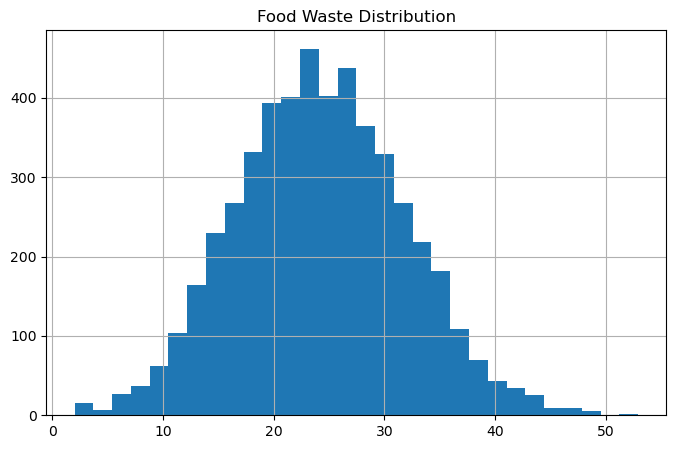

In [66]:
# Target distribution
plt.figure(figsize=(8, 5))
df["food_waste_kg"].hist(bins=30)
plt.title("Food Waste Distribution")

Text(0, 0.5, 'Frequency')

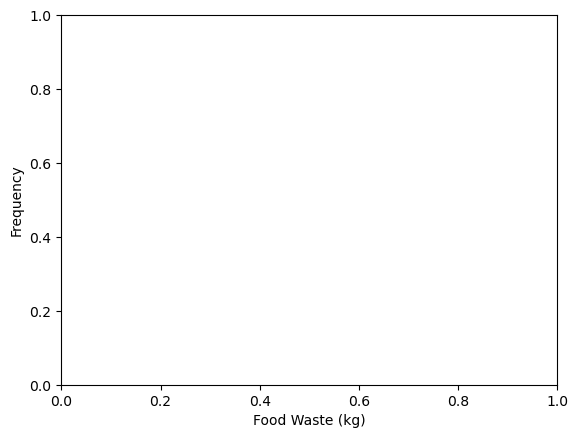

In [67]:
plt.xlabel("Food Waste (kg)")
plt.ylabel("Frequency")

In [68]:
plt.tight_layout()

<Figure size 640x480 with 0 Axes>

In [70]:
plt.savefig("outputs/food_waste_distribution.png", dpi=150)


<Figure size 640x480 with 0 Axes>

In [72]:
plt.close()

<Axes: xlabel='meal_type'>

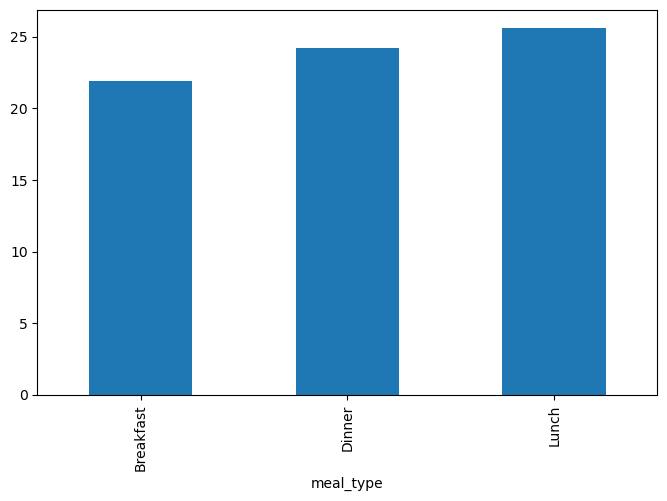

In [73]:
# Average waste by meal type
df.groupby("meal_type")["food_waste_kg"].mean().sort_values().plot(kind="bar", figsize=(8,5))

Text(0.5, 1.0, 'Average Food Waste by Meal Type')

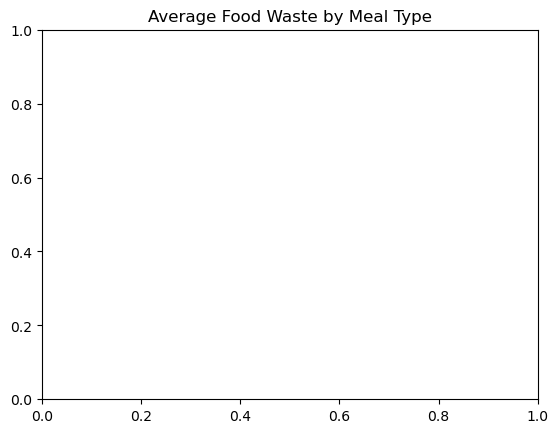

In [74]:
plt.title("Average Food Waste by Meal Type")

Text(0, 0.5, 'Average Waste (kg)')

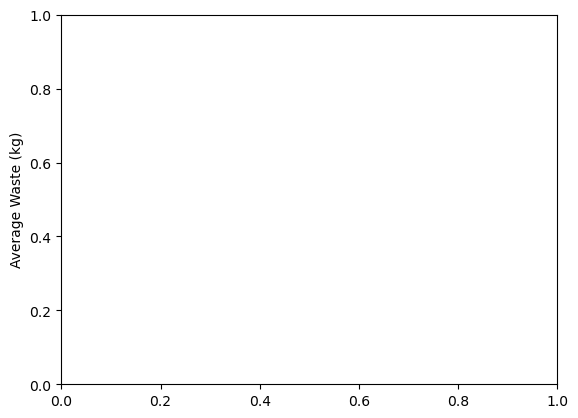

In [75]:
plt.ylabel("Average Waste (kg)")

In [77]:
plt.tight_layout()

<Figure size 640x480 with 0 Axes>

In [79]:
plt.savefig("outputs/waste_by_meal_type.png", dpi=150)


<Figure size 640x480 with 0 Axes>

In [80]:
plt.close()

<Axes: xlabel='menu_type'>

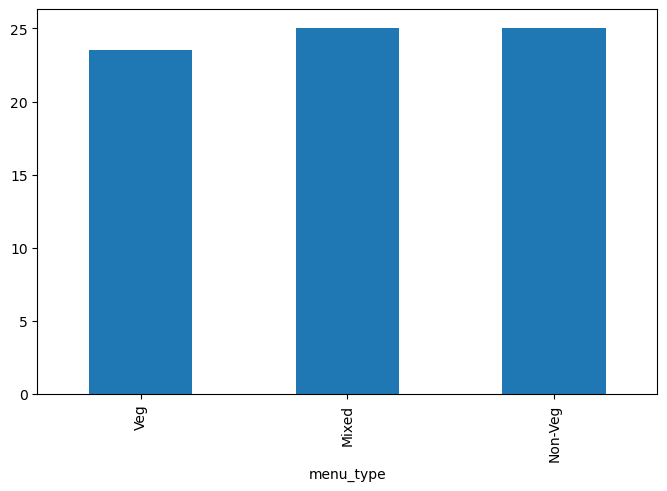

In [81]:
# Average waste by menu type
df.groupby("menu_type")["food_waste_kg"].mean().sort_values().plot(kind="bar", figsize=(8,5))


Text(0.5, 1.0, 'Average Food Waste by Menu Type')

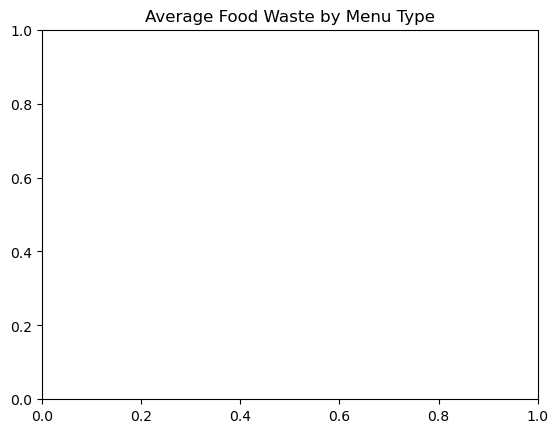

In [82]:

plt.title("Average Food Waste by Menu Type")

Text(0, 0.5, 'Average Waste (30kg)')

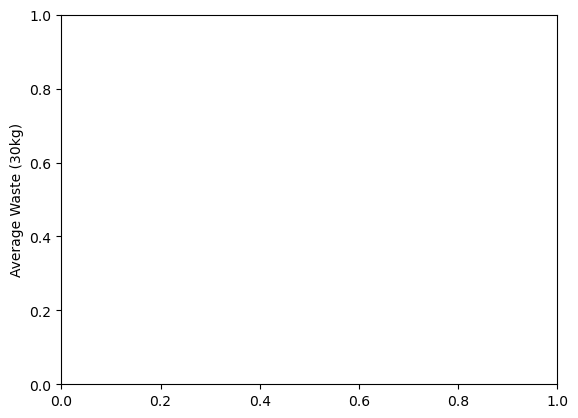

In [85]:
plt.ylabel("Average Waste (30kg)")

In [86]:
plt.tight_layout()

<Figure size 640x480 with 0 Axes>

In [87]:
plt.savefig("outputs/waste_by_menu_type.png", dpi=150)


<Figure size 640x480 with 0 Axes>

In [88]:

plt.close()

In [89]:
# Time trend
tmp = df.copy()

In [90]:
tmp = df.copy()
tmp["date"] = pd.to_datetime(tmp["date"])

In [91]:
daily = tmp.groupby("date")["food_waste_kg"].mean()

<Axes: xlabel='date'>

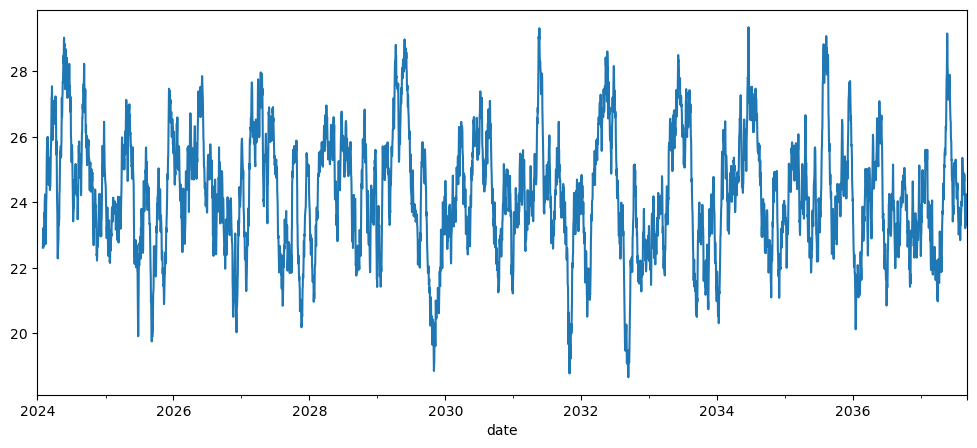

In [92]:
plt.figure(figsize=(12,5))
daily.rolling(30).mean().plot()

Text(0.5, 1.0, '30-Day Rolling Average of Food Waste')

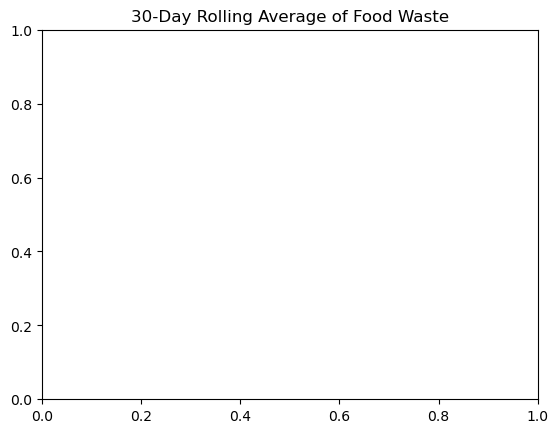

In [93]:
plt.title("30-Day Rolling Average of Food Waste")

Text(0, 0.5, 'Waste (kg)')

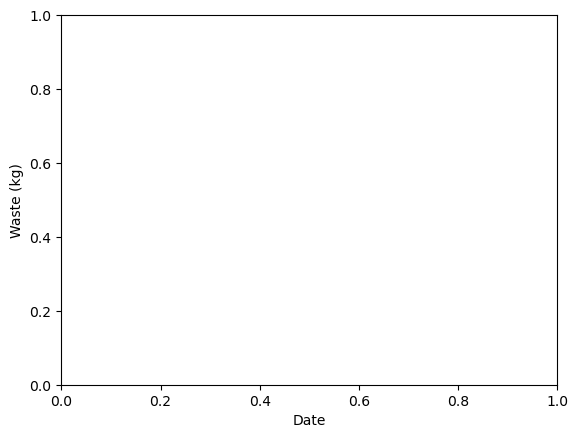

In [94]:
plt.xlabel("Date")
plt.ylabel("Waste (kg)")

In [95]:
plt.tight_layout()

<Figure size 640x480 with 0 Axes>

In [97]:
plt.savefig("outputs/waste_time_trend.png", dpi=150)


<Figure size 640x480 with 0 Axes>

In [98]:

plt.close()

In [99]:
print("\nEDA completed. Charts saved in outputs/")



EDA completed. Charts saved in outputs/
